<a href="https://colab.research.google.com/github/chandupradeep18/Python_pandas/blob/main/Analyze_Global_Development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas matplotlib seaborn

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
agd=pd.read_csv('https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv')

In [ ]:
print(agd.shape)
print(agd.columns.to_list())
print(agd.dtypes)
print(agd.sample())

(1704, 6)
['country', 'year', 'pop', 'continent', 'lifeExp', 'gdpPercap']
country       object
year           int64
pop          float64
continent     object
lifeExp      float64
gdpPercap    float64
dtype: object
     country  year        pop continent  lifeExp    gdpPercap
870  Lebanon  1982  3086876.0      Asia   66.983  7640.519521


In [ ]:
print(agd.describe())
print(agd.info())
print(agd['continent'].value_counts())

In [ ]:
print(agd.isnull().sum())
print(agd['country'].nunique())
print(agd['continent'].unique())
print(agd['year'].min(), agd['year'].max())

country      0
year         0
pop          0
continent    0
lifeExp      0
gdpPercap    0
dtype: int64
142
['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
1952 2007


In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=agd[agd['year'] == 2007], x='gdpPercap', y='lifeExp',
                hue='continent', size='pop', sizes=(20, 500), alpha=0.7)
plt.xscale('log')
plt.xlabel('GDP per Capita (USD, log scale)')
plt.ylabel('Life Expectancy (years)')
plt.title('Wealth vs Health of Nations (2007)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
continent_avg = agd.groupby(['year', 'continent'])['lifeExp'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=continent_avg, x='year', y='lifeExp', hue='continent', marker='o')
plt.xlabel('Year')
plt.ylabel('Average Life Expectancy (years)')
plt.title('Life Expectancy Trends by Continent (1952-2007)')
plt.tight_layout()
plt.show()

In [ ]:
top_gdp = agd[agd['year'] == 2007].nlargest(10, 'gdpPercap')

plt.figure(figsize=(10, 6))
sns.barplot(data=top_gdp, x='gdpPercap', y='country', hue='continent', dodge=False)
plt.xlabel('GDP per Capita (USD)')
plt.ylabel('')
plt.title('Top 10 Wealthiest Countries (2007)')
plt.tight_layout()
plt.show()

In [ ]:
summary_2007=agd[agd['year']==2007].groupby('continent').agg(
    avg_life_exp=('lifeExp','mean'),
    avg_gdp=('gdpPercap','mean'),
    total_pop=('pop','sum'),
    num_countries=('country','count')
).round(1)
print(summary_2007)

           avg_life_exp  avg_gdp     total_pop  num_countries
continent                                                    
Africa             54.8   3089.0  9.295397e+08             52
Americas           73.6  11003.0  8.988712e+08             25
Asia               70.7  12473.0  3.811954e+09             33
Europe             77.6  25054.5  5.860985e+08             30
Oceania            80.7  29810.2  2.454995e+07              2


In [ ]:
country_data = agd[agd['country'] == 'India']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(country_data['year'], country_data['lifeExp'], marker='o', color='coral')
axes[0].set_title("India: Life Expectancy Over Time")
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Life Expectancy (years)')

axes[1].plot(country_data['year'], country_data['gdpPercap'], marker='s', color='steelblue')
axes[1].set_title("India: GDP per Capita Over Time")
axes[1].set_xlabel('Year')
axes[1].set_ylabel('GDP per Capita (USD)')

plt.tight_layout()
plt.show()

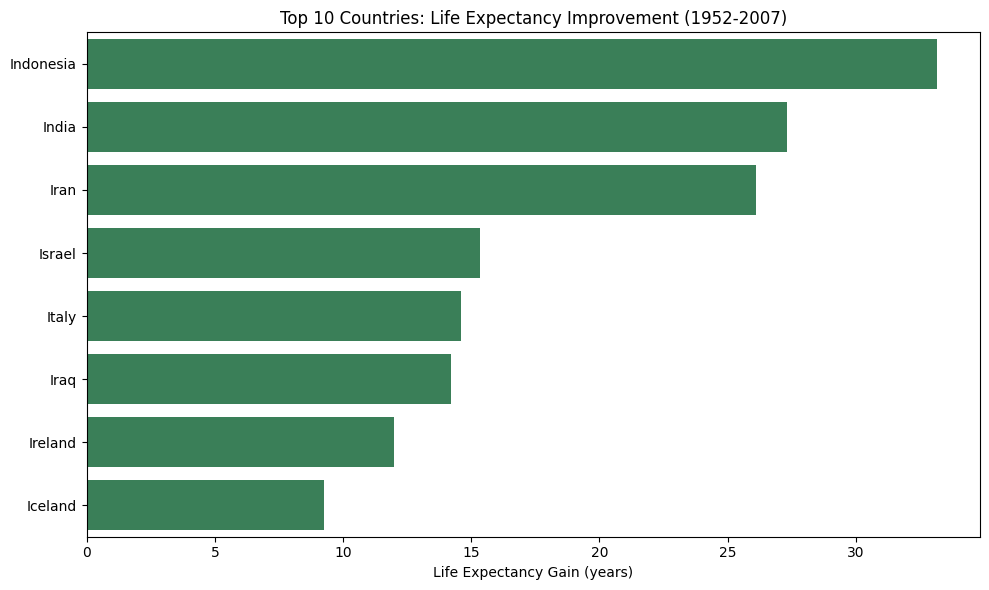

In [ ]:
life_exp_1952=agd[(agd['year']==1952) & agd['country'].astype(str).str.startswith('I') ][['country','lifeExp']].rename(columns={'lifeExp':'lifeExp_1952'})
life_exp_2007=agd[(agd['year']==2007) & agd['country'].astype(str).str.startswith('I') ][['country','lifeExp']].rename(columns={'lifeExp':'lifeExp_2007'})
improvement=life_exp_1952.merge(life_exp_2007,on='country')
improvement['gain']=improvement['lifeExp_2007']-improvement['lifeExp_1952']
top_improvers = improvement.nlargest(10, 'gain')
plt.figure(figsize=(10, 6))
sns.barplot(data=top_improvers, x='gain', y='country', color='seagreen')
plt.xlabel('Life Expectancy Gain (years)')
plt.ylabel('')
plt.title('Top 10 Countries: Life Expectancy Improvement (1952-2007)')
plt.tight_layout()
plt.show()

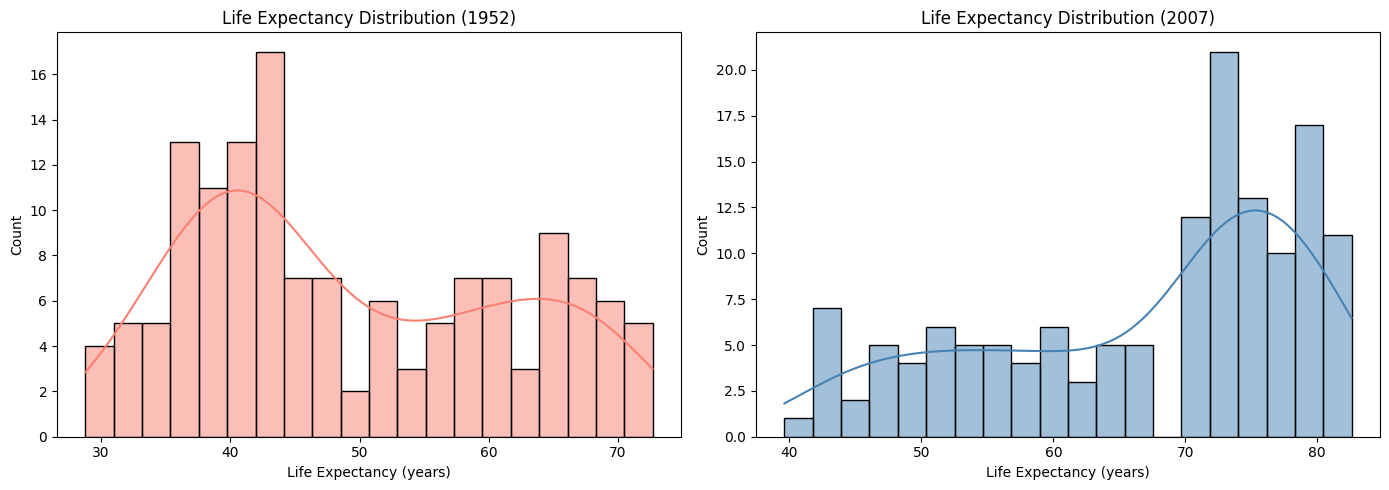

In [ ]:
# Compare life expectancy distributions: 1952 vs 2007
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1952 distribution with KDE curve
sns.histplot(data=agd[agd['year'] == 1952], x='lifeExp', bins=20, kde=True, ax=axes[0], color='salmon')
axes[0].set_title('Life Expectancy Distribution (1952)')
axes[0].set_xlabel('Life Expectancy (years)')

# 2007 distribution with KDE curve
sns.histplot(data=agd[agd['year'] == 2007], x='lifeExp', bins=20, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('Life Expectancy Distribution (2007)')
axes[1].set_xlabel('Life Expectancy (years)')

plt.tight_layout()
plt.show()

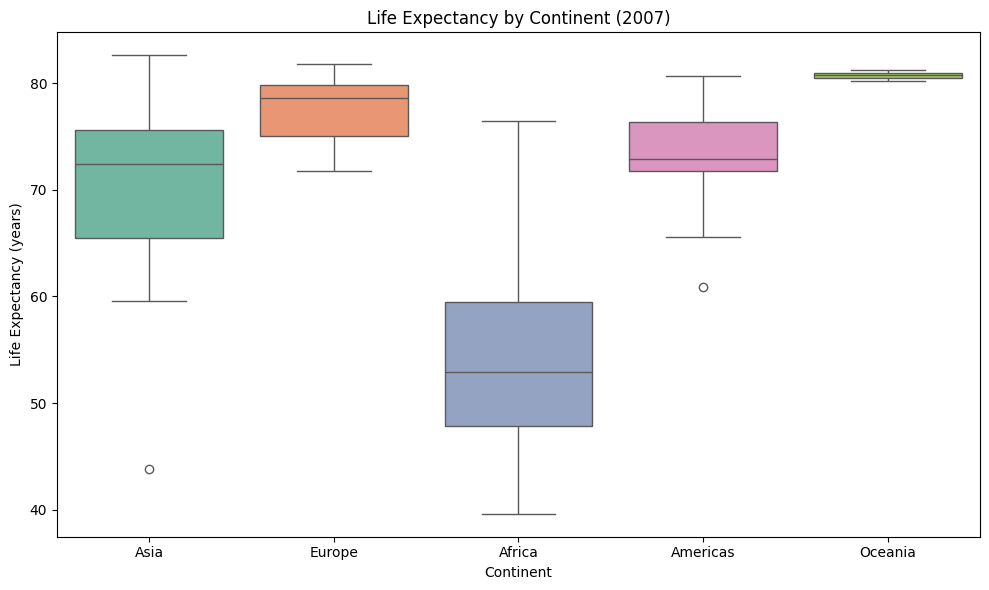

In [ ]:
# Box plot showing life expectancy spread within each continent
plt.figure(figsize=(10, 6))
sns.boxplot(data=agd[agd['year'] == 2007], x='continent', y='lifeExp', hue='continent', palette='Set2')
plt.xlabel('Continent')
plt.ylabel('Life Expectancy (years)')
plt.title('Life Expectancy by Continent (2007)')
plt.tight_layout()
plt.show()

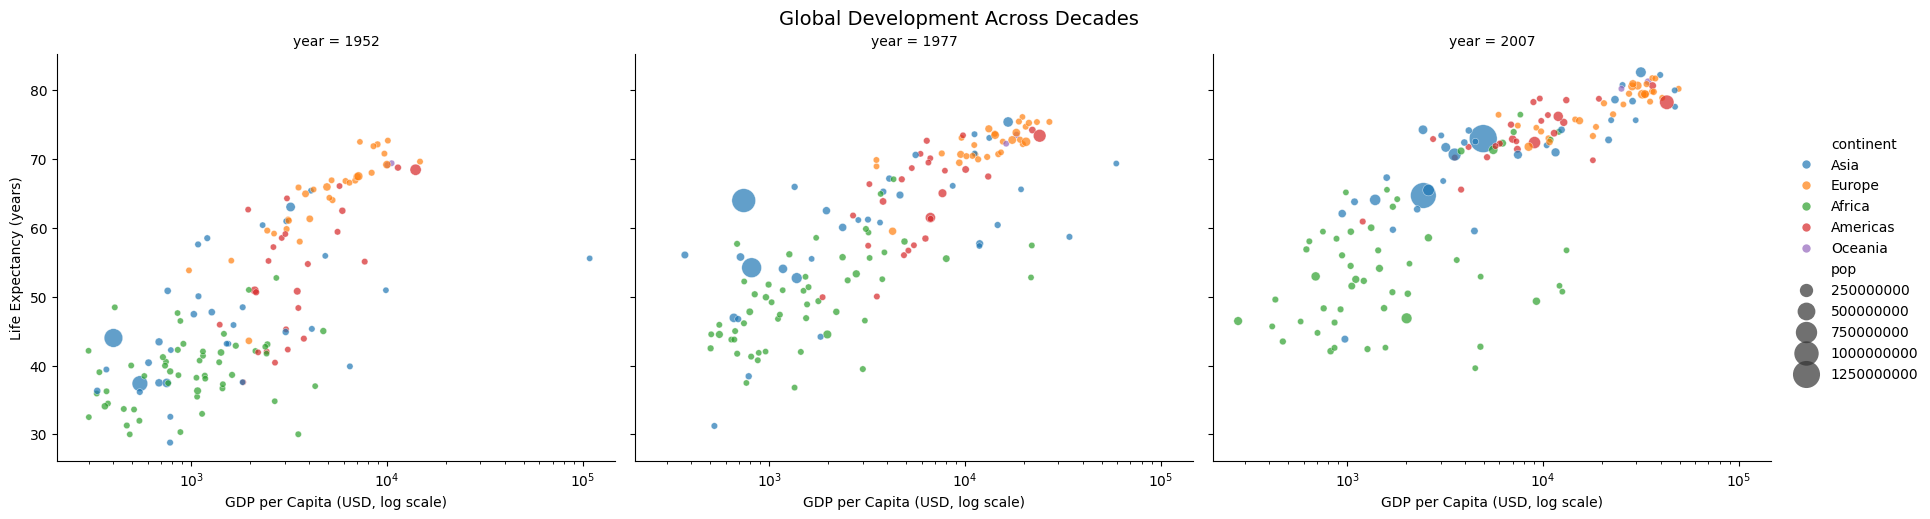

In [ ]:
selected_years =agd[agd['year'].isin([1952,1977, 2007])]
# Filter to three key decades

# Create a faceted scatter plot with one panel per year
g = sns.relplot(
    data=selected_years,
    x='gdpPercap', y='lifeExp',
    hue='continent', size='pop',
    sizes=(20, 400), alpha=0.7,
    col='year', col_wrap=3,
    height=5, aspect=1.2
)

# Apply log scale and set labels
g.set(xscale='log')
g.set_axis_labels('GDP per Capita (USD, log scale)', 'Life Expectancy (years)')
g.figure.suptitle('Global Development Across Decades', y=1.02, fontsize=14)

# Save the figure as a PNG
g.savefig('gapminder_faceted.png', dpi=150, bbox_inches='tight')
plt.show()